# Экзаменационная задача №06. Расчёт TCO и выбор инфраструктурной стратегии

**Дисциплина:** Экономика информатизации, лекция №7
**Студент:** Грошев Степан Сергеевич, группа БИ 5-1
**Дата:** 2026-11-12

In [1]:
# ======================================================================
# ЭКЗАМЕНАЦИОННАЯ ЗАДАЧА №06: РАСЧЁТ TCO И ВЫБОР ИНФРАСТРУКТУРНОЙ СТРАТЕГИИ
# ======================================================================
# Дисциплина: Экономика информатизации (лекция №7)
# Дата: 2026-11-12
# Студент: Грошев Степан Сергеевич
# Группа: БИ 5-1
# ======================================================================

# Подключение библиотек и общих утилит проекта
import sys, math
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # корень репозитория: utils/
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils.calculations import npv, irr, payback_period, discounted_payback_period, present_values, annuity_factor, fmt_rub
from utils.visualization import setup_style, thousands_axis, bar_labels, tornado, PALETTE
setup_style()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}".replace(",", " "))
pd.set_option("display.width", 140)

## 1. Экономическая постановка задачи

Компания «ТехноГос» выбирает инфраструктуру для госпортала на 5 лет: свой ЦОД (on-premise), облако (IaaS + PaaS) или гибрид.
У вариантов разная структура затрат. Свой ЦОД: много денег сразу (CAPEX) и мало потом (OPEX). Облако: почти только
ежегодные платежи, которые растут. Гибрид посередине. Сравнивать по цене покупки нельзя, нужна
**совокупная стоимость владения (TCO)** с учётом времени.

**Цель:** выбрать вариант с минимальной приведённой TCO и проверить, не поменяется ли выбор при других условиях.

Тема лекции №7: структура TCO (прямые и косвенные затраты), CAPEX и OPEX, дисконтирование, точка безубыточности.

## 2. Исходные данные

In [2]:
# 1.1. Параметры вариантов, млн руб. (из условия)
H = 5; r = 0.12
onprem = dict(capex=85.0, setup=12.0, energy=4.5, staff=9.0, sw_update=2.5, training=1.5, downtime=3.0, modern=8.0)
cloud = dict(setup=5.0, cloud=16.0, growth=0.05, staff=4.0, support=2.5, training=2.0)
hybrid = dict(capex=35.0, setup=8.0, cloud=8.0, ops=3.0, staff=6.0, support=2.0, modern=4.0)
prop_tax = 0.022; dep_years = 5
pd.DataFrame({"On-premise": pd.Series(onprem), "Облако": pd.Series(cloud), "Гибрид": pd.Series(hybrid)})

,On-premise,Облако,Гибрид
capex,85.00,NaN,35.00
cloud,NaN,16.00,8.00
downtime,3.00,NaN,NaN
energy,4.50,NaN,NaN
growth,NaN,0.05,NaN
modern,8.00,NaN,4.00
ops,NaN,NaN,3.00
setup,12.00,5.00,8.00
staff,9.00,4.00,6.00
support,NaN,2.50,2.00


**Допущения:**
- Год 0: разовые затраты (покупка, настройка, миграция). Годы 1–5: текущие затраты в конце года. Обучение в 1-м году
  (как в условии), модернизация в 3-м году.
- Налог на имущество 2,2 % от **среднегодовой остаточной стоимости** оборудования, амортизация линейная за 5 лет.
  Для on-premise база 85 млн руб. (в условии оборудование и ПО не разделены, берём всю сумму, это осторожная оценка).
  Для гибрида налог тоже начисляем на своё оборудование 35 млн руб., его требует НК РФ. Вариант без налога показан отдельно.
- Облако дорожает на 5 % в год, начиная со 2-го года.

## 3. Математическая модель

$$TCO_{PV} = \sum_{t=0}^{5}\frac{C_t}{(1+r)^t},\qquad C_t = CAPEX_t + OPEX_t + Налог_t$$
$$Налог_t = 0{,}022\cdot\Big(K - \tfrac{K}{5}(t-0{,}5)\Big),\qquad Облако_t = 16\cdot1{,}05^{\,t-1}$$
Точка безубыточности это срок $T^*$, на котором накопленные приведённые затраты двух вариантов сравниваются:
$\sum_{t\le T^*}PV(C^{on-prem}_t) = \sum_{t\le T^*}PV(C^{облако}_t)$.

## 4. Реализация расчёта
### 4.1. Денежные потоки по вариантам

In [3]:
def avg_residual_tax(capex, t):
    """Налог на имущество за год t: 2.2% от среднегодовой остаточной стоимости."""
    if t < 1 or t > dep_years:
        return 0.0
    return prop_tax * max(capex - capex / dep_years * (t - 0.5), 0)

def flows_onprem(years=H, p=onprem, extend=False):
    rows = []
    for t in range(years + 1):
        row = {"Год": t, "Оборудование и ПО": p["capex"] if t == 0 else 0, "Настройка": p["setup"] if t == 0 else 0,
               "Эксплуатация": p["energy"] if t else 0, "Персонал": p["staff"] if t else 0,
               "Обновление ПО": p["sw_update"] if t else 0, "Обучение": p["training"] if t == 1 else 0,
               "Простои": p["downtime"] if t else 0,
               "Модернизация": p["modern"] if (t and t % 3 == 0 and (extend or t == 3)) else 0,
               "Налог на имущество": avg_residual_tax(p["capex"], t)}
        rows.append(row)
    return pd.DataFrame(rows).set_index("Год")

def flows_cloud(years=H, p=cloud, k_cloud=1.0):
    rows = []
    for t in range(years + 1):
        rows.append({"Год": t, "Миграция": p["setup"] if t == 0 else 0,
                     "Облачные услуги": p["cloud"] * k_cloud * (1 + p["growth"]) ** (t - 1) if t else 0,
                     "Персонал": p["staff"] if t else 0, "Поддержка": p["support"] if t else 0,
                     "Обучение": p["training"] if t == 1 else 0})
    return pd.DataFrame(rows).set_index("Год")

def flows_hybrid(years=H, p=hybrid, k_cloud=1.0, tax=True, extend=False):
    rows = []
    for t in range(years + 1):
        rows.append({"Год": t, "Оборудование": p["capex"] if t == 0 else 0, "Настройка": p["setup"] if t == 0 else 0,
                     "Облачные услуги": p["cloud"] * k_cloud if t else 0, "Эксплуатация": p["ops"] if t else 0,
                     "Персонал": p["staff"] if t else 0, "Поддержка": p["support"] if t else 0,
                     "Модернизация": p["modern"] if (t and t % 3 == 0 and (extend or t == 3)) else 0,
                     "Налог на имущество": avg_residual_tax(p["capex"], t) if tax else 0})
    return pd.DataFrame(rows).set_index("Год")

F = {"On-premise": flows_onprem(), "Облако": flows_cloud(), "Гибрид": flows_hybrid()}
for name, df in F.items():
    df["ИТОГО"] = df.sum(axis=1)
    print(f"\n{name}, млн руб."); display(df.round(2))


On-premise, млн руб.


,Оборудование и ПО,Настройка,Эксплуатация,Персонал,Обновление ПО,Обучение,Простои,Модернизация,Налог на имущество,ИТОГО
Год,,,,,,,,,,
0,85.00,12.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,97.00
1,0.00,0.00,4.50,9.00,2.50,1.50,3.00,0.00,1.68,22.18
2,0.00,0.00,4.50,9.00,2.50,0.00,3.00,0.00,1.31,20.31
3,0.00,0.00,4.50,9.00,2.50,0.00,3.00,8.00,0.94,27.94
4,0.00,0.00,4.50,9.00,2.50,0.00,3.00,0.00,0.56,19.56
5,0.00,0.00,4.50,9.00,2.50,0.00,3.00,0.00,0.19,19.19



Облако, млн руб.


,Миграция,Облачные услуги,Персонал,Поддержка,Обучение,ИТОГО
Год,,,,,,
0,5.00,0.00,0.00,0.00,0.00,5.00
1,0.00,16.00,4.00,2.50,2.00,24.50
2,0.00,16.80,4.00,2.50,0.00,23.30
3,0.00,17.64,4.00,2.50,0.00,24.14
4,0.00,18.52,4.00,2.50,0.00,25.02
5,0.00,19.45,4.00,2.50,0.00,25.95



Гибрид, млн руб.


,Оборудование,Настройка,Облачные услуги,Эксплуатация,Персонал,Поддержка,Модернизация,Налог на имущество,ИТОГО
Год,,,,,,,,,
0,35.00,8.00,0.00,0.00,0.00,0.00,0.00,0.00,43.00
1,0.00,0.00,8.00,3.00,6.00,2.00,0.00,0.69,19.69
2,0.00,0.00,8.00,3.00,6.00,2.00,0.00,0.54,19.54
3,0.00,0.00,8.00,3.00,6.00,2.00,4.00,0.38,23.38
4,0.00,0.00,8.00,3.00,6.00,2.00,0.00,0.23,19.23
5,0.00,0.00,8.00,3.00,6.00,2.00,0.00,0.08,19.08


### 4.2. Дисконтирование и итоговая TCO

In [4]:
def tco(df, rate=r):
    total = df.drop(columns="ИТОГО", errors="ignore").sum(axis=1).values
    return total.sum(), npv(total, rate)

res = pd.DataFrame({name: dict(zip(["TCO номинал, млн", "TCO дисконт. (12%), млн"], tco(df))) for name, df in F.items()}).T
res["CAPEX года 0, млн"] = [df.loc[0, "ИТОГО"] for df in F.values()]
res["Ранг"] = res["TCO дисконт. (12%), млн"].rank().astype(int)
res["Экономия к on-premise, %"] = (1 - res["TCO дисконт. (12%), млн"] / res.loc["On-premise", "TCO дисконт. (12%), млн"]) * 100
hyb_no_tax = tco(flows_hybrid(tax=False))[1]
print(f"Гибрид без налога на имущество: {hyb_no_tax:.2f} млн руб.")
res.round(2)

Гибрид без налога на имущество: 114.34 млн руб.


,"TCO номинал, млн","TCO дисконт. (12%), млн","CAPEX года 0, млн",Ранг,"Экономия к on-premise, %"
On-premise,206.18,176.20,97.00,3,0.00
Облако,127.91,93.26,5.00,1,47.07
Гибрид,143.93,115.85,43.00,2,34.25


### 4.3. Точка безубыточности: on-premise против облака

За 5 лет накопленные затраты своего ЦОДа выше облака в каждом году. Продлим срок до 15 лет при таких допущениях:
оборудование не меняем (только модернизация раз в 3 года), после 5-го года налог на имущество не платим
(оборудование самортизировано), облако дальше дорожает на 5 % в год.

In [5]:
cum = pd.DataFrame({name: present_values(df["ИТОГО"].values, r).cumsum() for name, df in F.items()})
cum.index.name = "Год"
cum["Разница on-prem − облако"] = cum["On-premise"] - cum["Облако"]
display(cum.round(2))

long_H = 15
on_long = flows_onprem(long_H, extend=True).sum(axis=1).values
cl_long = flows_cloud(long_H).sum(axis=1).values
diff_disc = np.cumsum(present_values(on_long, r)) - np.cumsum(present_values(cl_long, r))
diff_nom = np.cumsum(on_long) - np.cumsum(cl_long)
be_disc = next((t for t, d in enumerate(diff_disc) if d <= 0), None)
be_nom = next((t for t, d in enumerate(diff_nom) if d <= 0), None)
print(f"Безубыточность (номинально): год {be_nom}" if be_nom else "Номинально: не достигается за 15 лет")
print(f"Безубыточность (дисконт., 12%): год {be_disc}" if be_disc else "С дисконтированием: не достигается за 15 лет")
print(f"Средняя ежегодная экономия on-premise против облака в годах 6–15: {(cl_long[6:] - on_long[6:]).mean():.1f} млн руб.")

,On-premise,Облако,Гибрид,Разница on-prem − облако
Год,,,,
0,97.00,5.00,43.00,92.00
1,116.81,26.88,60.58,89.93
2,133.00,45.45,76.16,87.55
3,152.88,62.63,92.80,90.25
4,165.31,78.53,105.03,86.78
5,176.20,93.26,115.85,82.94


Безубыточность (номинально): год 14
С дисконтированием: не достигается за 15 лет
Средняя ежегодная экономия on-premise против облака в годах 6–15: 10.0 млн руб.


### 4.4. Анализ чувствительности

In [6]:
rate_sens = pd.DataFrame({f"{int(rt*100)}%": {name: tco(df, rt)[1] for name, df in F.items()} for rt in [0.08, 0.12, 0.16]}).T
rate_sens["Лучший"] = rate_sens.idxmin(axis=1)
display(rate_sens.round(2))
cloud_sens = []
for kc in [0.8, 1.0, 1.2]:
    c_ = tco(flows_cloud(k_cloud=kc))[1]; h_ = tco(flows_hybrid(k_cloud=kc))[1]; o_ = res.loc["On-premise", "TCO дисконт. (12%), млн"]
    cloud_sens.append({"Цена облака": f"{kc-1:+.0%}", "On-premise": o_, "Облако": c_, "Гибрид": h_,
                       "Лучший": min([("On-premise", o_), ("Облако", c_), ("Гибрид", h_)], key=lambda x: x[1])[0]})
cloud_sens = pd.DataFrame(cloud_sens).set_index("Цена облака")
# При каком росте цены облака оно сравняется с гибридом?
from utils.calculations import solve_for
k_eq = solve_for(lambda k: tco(flows_cloud(k_cloud=k))[1] - tco(flows_hybrid(k_cloud=k))[1], 0, 0.5, 5)
print(f"Облако сравнивается с гибридом при росте цены облачных услуг на {k_eq-1:.0%}")
cloud_sens.round(2)

,On-premise,Облако,Гибрид,Лучший
8%,184.56,102.88,123.67,Облако
12%,176.20,93.26,115.85,Облако
16%,169.05,85.08,109.18,Облако


Облако сравнивается с гибридом при росте цены облачных услуг на 66%


,On-premise,Облако,Гибрид,Лучший
Цена облака,,,,
-20%,176.20,80.65,110.08,Облако
+0%,176.20,93.26,115.85,Облако
+20%,176.20,105.87,121.62,Облако


## 5. Визуализация результатов

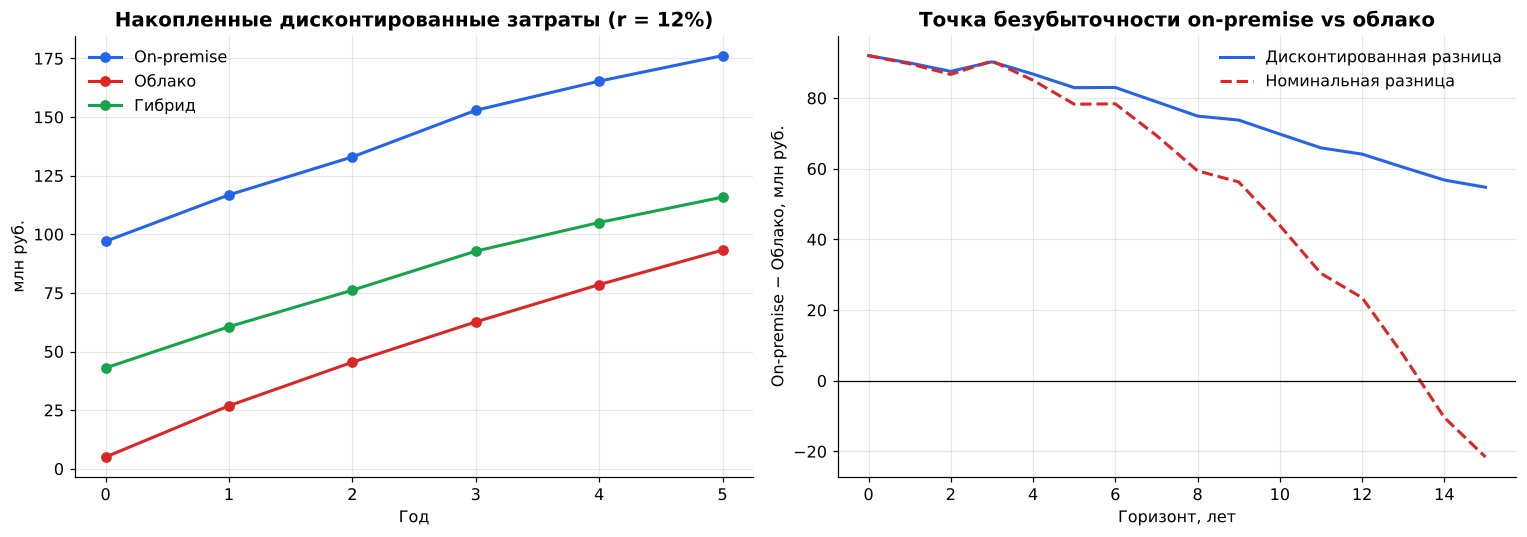

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
for name in F:
    ax.plot(cum.index, cum[name], "o-", lw=2, label=name)
ax.set_xlabel("Год"); ax.set_ylabel("млн руб."); ax.set_title("Накопленные дисконтированные затраты (r = 12%)"); ax.legend()
ax = axes[1]
ax.plot(range(long_H + 1), diff_disc, lw=2, label="Дисконтированная разница")
ax.plot(range(long_H + 1), diff_nom, lw=2, ls="--", label="Номинальная разница")
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Горизонт, лет"); ax.set_ylabel("On-premise − Облако, млн руб."); ax.set_title("Точка безубыточности on-premise vs облако")
ax.legend()
plt.tight_layout(); plt.show()

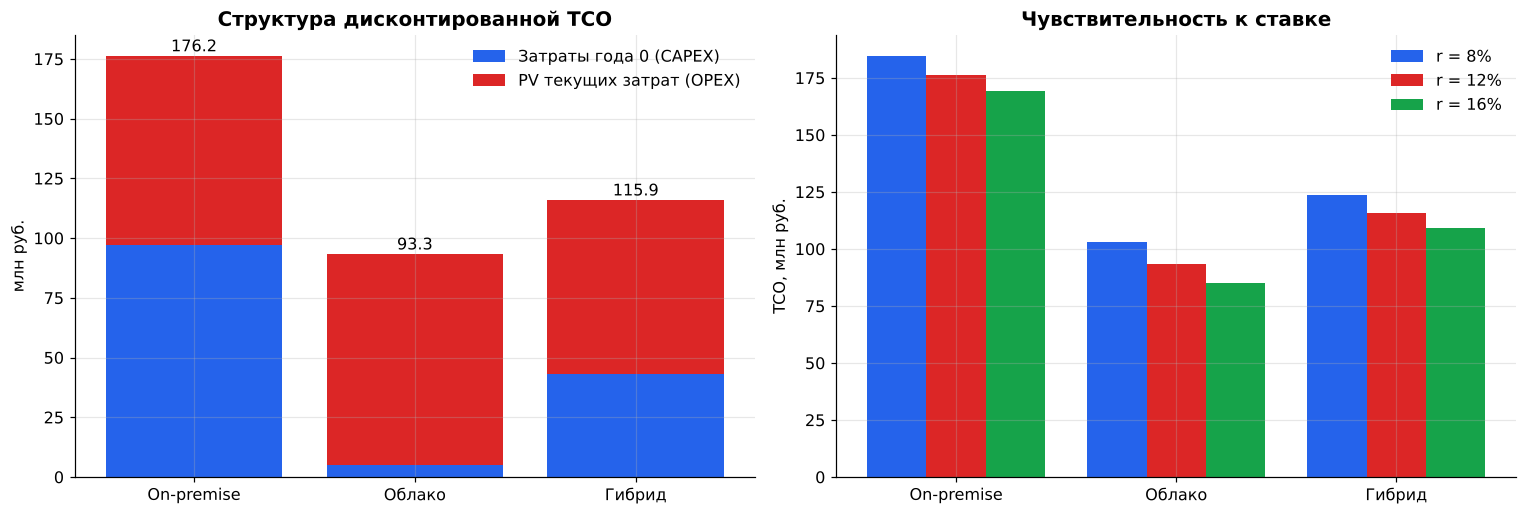

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
ax = axes[0]
capex_part = [F["On-premise"].loc[0, "ИТОГО"], F["Облако"].loc[0, "ИТОГО"], F["Гибрид"].loc[0, "ИТОГО"]]
pv_total = res["TCO дисконт. (12%), млн"].values
b1 = ax.bar(res.index, capex_part, label="Затраты года 0 (CAPEX)")
b2 = ax.bar(res.index, pv_total - capex_part, bottom=capex_part, label="PV текущих затрат (OPEX)")
for i, v in enumerate(pv_total): ax.text(i, v + 2, f"{v:.1f}", ha="center")
ax.set_ylabel("млн руб."); ax.set_title("Структура дисконтированной TCO"); ax.legend()
ax = axes[1]
x = np.arange(3); w = 0.27
for i, rt in enumerate(rate_sens.index):
    ax.bar(x + (i - 1) * w, rate_sens.loc[rt, ["On-premise", "Облако", "Гибрид"]].astype(float), w, label=f"r = {rt}")
ax.set_xticks(x, ["On-premise", "Облако", "Гибрид"]); ax.set_ylabel("TCO, млн руб."); ax.set_title("Чувствительность к ставке")
ax.legend()
plt.tight_layout(); plt.show()

## 6. Интерпретация результатов

- **Самая низкая TCO у облака**, на втором месте гибрид, самый дорогой свой ЦОД. Приведённая TCO: облако 93 млн руб.,
  гибрид 116 млн, on-premise 176 млн. Облако дешевле своего ЦОДа примерно на 47 %. Главная причина: огромные вложения
  в свой ЦОД в году 0 (около 97 млн руб.), а ежегодные затраты у вариантов похожи (19–26 млн руб. в год).
- **Точки безубыточности** за 5 лет нет. Если продлить срок, свой ЦОД начинает догонять только после полной амортизации,
  потому что ежегодно он дешевле. Без дисконтирования он догоняет облако только на 14-м году, а с дисконтированием (12 %)
  не догоняет и за 15 лет. И это если серверы не придётся менять, что нереально: обычно они служат 5–7 лет.
- **Ставка дисконтирования** выбор не меняет: облако лучше при 8, 12 и 16 %. Чем выше ставка, тем сильнее она бьёт
  по крупным начальным вложениям, и преимущество облака только растёт.
- **Цена облака ±20 %** тоже ничего не меняет: облако всё равно намного дешевле своего ЦОДа. С гибридом облако сравняется,
  только если облачные цены вырастут примерно на 66 %.

## 7. Выводы и рекомендации

**Рекомендуем облако (IaaS + PaaS):** самая низкая TCO, мало денег на старте (около 5 млн руб. против 97 млн),
легко масштабироваться, затраты становятся текущими, нет риска, что оборудование устареет.

**Что ещё учесть до решения**
| Фактор | Как влияет |
|---|---|
| 152-ФЗ, требования ФСТЭК, класс защищённости ГИС | облако должно быть аттестованным (гособлако или сертифицированный провайдер), иначе гибрид |
| Зависимость от провайдера и рост тарифов | долгий контракт с фиксированной ценой, план переезда |
| Срок больше 7–10 лет и ровная нагрузка | преимущество облака меньше, пересмотреть решение на 5-м году |
| Пики нагрузки (сезонные сервисы) | ещё один плюс облака: мощности добавляются по требованию |
| Кадры | обучить администраторов облаку, сократить штат ЦОДа |
| Надёжность и SLA | штрафы в договоре, резерв в двух зонах доступности |

**План:** выбрать сертифицированного провайдера, пилот на 3 месяца, переезд, затем каждый год пересчитывать TCO
и договариваться о тарифах. Самые чувствительные данные при необходимости держать в своём сегменте (элемент гибрида).